# 14 — Portfolio Construction

Notebook này xây dựng danh mục từ watchlist bằng tối ưu hóa Scipy và giả lập Monte Carlo.

In [3]:
# Cell: Setup Project Root
import os
import sys
from pathlib import Path

def find_project_root(start_path=None):
    path = Path(start_path or os.getcwd()).resolve()
    for parent in [path, *path.parents]:
        if (parent / "src").is_dir() and (parent / "config").is_dir():
            return parent
    raise FileNotFoundError("Khong tim thay project root co thu muc src/ va config/")

project_root = find_project_root()
os.chdir(project_root)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

print("Project root:", project_root)

Project root: /Users/jamesb/Desktop/vietnam-quant-research


In [4]:
# Cell: Import Portfolio Modules
import pandas as pd

from src.analytics.correlation import build_return_matrix
from src.data.loaders import read_parquet
from src.portfolio.construction import (
    equal_weight_allocation,
    hierarchical_risk_parity_allocation,
    inverse_volatility_allocation,
    portfolio_risk_contributions,
    risk_parity_allocation,
    shrink_covariance,
    maximize_sharpe_ratio,
    efficient_frontier,
)
from src.portfolio import (
    calculate_returns_matrix,
    estimate_expected_returns,
    calculate_portfolio_return,
    calculate_covariance_matrix,
    calculate_correlation_matrix,
    calculate_portfolio_variance,
    calculate_portfolio_volatility,
    calculate_risk_contribution,
    equal_weight_portfolio,
    optimize_max_return_under_risk,
    optimize_min_risk_for_target_return,
    optimize_max_sharpe,
    check_weight_constraints,
    check_risk_constraint,
    check_sector_constraints,
    check_liquidity_constraints,
    check_turnover_constraint,
    generate_portfolio_summary,
    generate_constraint_check_table,
    generate_risk_contribution_table,
    generate_correlation_report,
    generate_random_weights,
    evaluate_portfolio,
    generate_random_portfolios,
    select_best_portfolio,
    generate_sub_portfolios
)
from src.reporting.chart_factory import risk_contribution_chart, weight_bar_chart


In [5]:
# Cell: Load Universe And Returns
# User custom watchlist option. Set to a list of symbols to override, or None to use default trade card candidates.
user_watchlist = [
    "NAB", "VCB", "SAB", "STB", "POW",
    "SSB", "OCB", "KLB", "MSB", "VAB",
    "MCM", "VIB", "LAF", "BID", "MBB",
    "ASP", "VIC", "BWE", "GEG", "TCB"
]

signals = read_parquet("data/signals/setup_signals.parquet")
volatility_df = read_parquet("data/processed/stock_features_volatility.parquet")
trade_cards = read_parquet("data/signals/breakout_20d_trade_cards.parquet")

if signals.empty:
    raise FileNotFoundError("Khong tim thay data/signals/setup_signals.parquet")

signals["date"] = pd.to_datetime(signals["date"])
if not volatility_df.empty:
    volatility_df["date"] = pd.to_datetime(volatility_df["date"])
    enrich_cols = [col for col in ["volatility_regime", "volatility_percentile", "atr_pct_14"] if col in volatility_df.columns and col not in signals.columns]
    if enrich_cols:
        signals = signals.merge(volatility_df[["symbol", "date", *enrich_cols]], on=["symbol", "date"], how="left")

latest_trade_cards = trade_cards.copy() if not trade_cards.empty else pd.DataFrame()

if user_watchlist is not None:
    candidate_symbols = [sym.upper() for sym in user_watchlist]
    print(f"Using manual user watchlist: {candidate_symbols}")
elif not latest_trade_cards.empty:
    latest_trade_cards["date"] = pd.to_datetime(latest_trade_cards["date"])
    candidate_symbols = latest_trade_cards.loc[latest_trade_cards["edge_tier"].isin(["Strong Edge", "Valid Edge", "Emerging Edge", "Conditional Edge"]), "symbol"].dropna().unique().tolist()
else:
    candidate_symbols = signals["symbol"].dropna().unique().tolist()

analysis_df = signals[signals["symbol"].isin(candidate_symbols)].copy()
return_matrix = build_return_matrix(analysis_df, return_col="return_1d")
return_matrix = return_matrix.dropna(how="all").fillna(0.0)
cov_matrix = shrink_covariance(return_matrix.cov(), shrinkage=0.15)
latest_vol = analysis_df.sort_values(["symbol", "date"]).groupby("symbol").tail(1).set_index("symbol")["atr_pct_14"].dropna()

print("Candidate symbols:", candidate_symbols)
print("Returns matrix shape:", return_matrix.shape)


Using manual user watchlist: ['NAB', 'VCB', 'SAB', 'STB', 'POW', 'SSB', 'OCB', 'KLB', 'MSB', 'VAB', 'MCM', 'VIB', 'LAF', 'BID', 'MBB', 'ASP', 'VIC', 'BWE', 'GEG', 'TCB']
Candidate symbols: ['NAB', 'VCB', 'SAB', 'STB', 'POW', 'SSB', 'OCB', 'KLB', 'MSB', 'VAB', 'MCM', 'VIB', 'LAF', 'BID', 'MBB', 'ASP', 'VIC', 'BWE', 'GEG', 'TCB']
Returns matrix shape: (1608, 20)


In [6]:
# Cell: Build Allocations
symbols = cov_matrix.columns.tolist()
equal_weights = equal_weight_portfolio(symbols)
inv_vol_weights = inverse_volatility_allocation(latest_vol.reindex(symbols).fillna(latest_vol.median()))
risk_parity_weights = risk_parity_allocation(cov_matrix)
hrp_weights = hierarchical_risk_parity_allocation(returns=return_matrix[symbols])

# Calculate annualized expected returns using new returns module
expected_returns = estimate_expected_returns(return_matrix[symbols], annualized=True)

# Max Sharpe ratio optimization (caps weights at 25%)
max_sharpe_weights = optimize_max_sharpe(
    expected_returns=expected_returns,
    covariance=cov_matrix,
    risk_free_rate=0.03,
    max_weight=0.25,
)

# Objective 1: Maximize return under 10% risk limit
max_ret_under_risk_weights = optimize_max_return_under_risk(
    expected_returns=expected_returns,
    covariance=cov_matrix,
    max_volatility=0.10,
    max_weight=0.25,
)

# Objective 2: Minimize risk for 15% target expected return
min_risk_target_ret_weights = optimize_min_risk_for_target_return(
    expected_returns=expected_returns,
    covariance=cov_matrix,
    target_return=0.15,
    max_weight=0.25,
)

weights_table = pd.concat(
    [
        equal_weights.rename("equal_weight"),
        inv_vol_weights.rename("inverse_vol"),
        risk_parity_weights.rename("risk_parity"),
        hrp_weights.rename("hrp"),
        max_sharpe_weights.rename("max_sharpe"),
        max_ret_under_risk_weights.rename("max_ret_under_risk"),
        min_risk_target_ret_weights.rename("min_risk_target_ret"),
    ],
    axis=1,
).fillna(0.0)
weights_table

,equal_weight,inverse_vol,risk_parity,hrp,max_sharpe,max_ret_under_risk,min_risk_target_ret
ASP,0.05,0.028965,0.075157,0.071225,1.291017e-01,1.182540e-01,0.044493
BID,0.05,0.051432,0.012432,0.007362,1.368154e-16,0.000000e+00,0.034626
BWE,0.05,0.067084,0.117062,0.143804,1.371884e-16,1.880718e-16,0.012899
GEG,0.05,0.054682,0.069821,0.048487,3.275240e-17,0.000000e+00,0.020129
KLB,0.05,0.037514,0.054904,0.031276,1.373306e-01,1.570254e-01,0.063408
LAF,0.05,0.040331,0.138059,0.129841,8.252529e-02,1.617969e-02,0.034103
MBB,0.05,0.086785,0.051960,0.069645,1.919585e-01,2.086702e-01,0.060621
MCM,0.05,0.060057,0.147748,0.204177,4.625657e-17,3.632755e-17,0.022118
MSB,0.05,0.043738,0.010865,0.012862,3.467436e-02,4.653113e-02,0.055984
NAB,0.05,0.050505,0.008484,0.005458,2.006619e-16,9.571133e-17,0.049769


In [7]:
# Cell: Visualize Allocations
display(weight_bar_chart(weights_table["risk_parity"], title="Risk Parity Weights"))
display(weight_bar_chart(weights_table["hrp"], title="HRP Weights"))
display(weight_bar_chart(weights_table["max_ret_under_risk"], title="Max Return under Vol Constraint (Objective 1) Weights"))


In [8]:
# Cell: Risk Contribution & Correlation Review
# 1. Risk Contribution Table for Max Sharpe
max_sharpe_rc = generate_risk_contribution_table(weights_table["max_sharpe"], cov_matrix)
print("--- Risk Contributions (Max Sharpe) ---")
display(max_sharpe_rc)

# 2. Risk Contribution Table for Max Return under Risk Limit
max_ret_risk_rc = generate_risk_contribution_table(weights_table["max_ret_under_risk"], cov_matrix)
print("--- Risk Contributions (Max Return under Risk Limit) ---")
display(max_ret_risk_rc)

# 3. Correlation report for the portfolio assets
corr_report = generate_correlation_report(return_matrix[symbols])
print("\n--- Correlation Report ---")
print(f"Average pairwise correlation: {corr_report['average_pairwise_correlation']:.2f}")
print(f"Max correlation: {corr_report['max_correlation']:.2f} (Pair: {corr_report['max_correlation_pair']})")
if corr_report["high_correlation_alerts"]:
    print("WARNING: High correlation pairs detected:")
    for alert in corr_report["high_correlation_alerts"]:
        print(f"  {alert}")


--- Risk Contributions (Max Sharpe) ---


,symbol,weight,marginal_contribution,total_contribution,risk_contribution_pct
0,ASP,1.291017e-01,0.002422,3.126712e-04,5.569361e+00
1,BID,1.368154e-16,0.002797,3.826451e-19,6.815750e-15
2,BWE,1.371884e-16,0.000618,8.476362e-20,1.509826e-15
3,GEG,3.275240e-17,0.001518,4.970327e-20,8.853245e-16
4,KLB,1.373306e-01,0.004844,6.652811e-04,1.185012e+01
5,LAF,8.252529e-02,0.001093,9.021733e-05,1.606969e+00
6,MBB,1.919585e-01,0.004486,8.611201e-04,1.533844e+01
7,MCM,4.625657e-17,0.000772,3.573270e-20,6.364780e-16
8,MSB,3.467436e-02,0.003899,1.351931e-04,2.408087e+00
9,NAB,2.006619e-16,0.006908,1.386144e-18,2.469027e-14


--- Risk Contributions (Max Return under Risk Limit) ---


,symbol,weight,marginal_contribution,total_contribution,risk_contribution_pct
0,ASP,1.182540e-01,0.002074,2.452021e-04,3.892462e+00
1,BID,0.000000e+00,0.002453,0.000000e+00,0.000000e+00
2,BWE,1.880718e-16,0.000577,1.084237e-19,1.721173e-15
3,GEG,0.000000e+00,0.001366,0.000000e+00,0.000000e+00
4,KLB,1.570254e-01,0.004734,7.433433e-04,1.180021e+01
5,LAF,1.617969e-02,0.000600,9.700449e-06,1.539898e-01
6,MBB,2.086702e-01,0.004341,9.059373e-04,1.438131e+01
7,MCM,3.632755e-17,0.000740,2.689040e-20,4.268718e-16
8,MSB,4.653113e-02,0.003701,1.722051e-04,2.733670e+00
9,NAB,9.571133e-17,0.007219,6.909257e-19,1.096810e-14



--- Correlation Report ---
Average pairwise correlation: 0.08
Max correlation: 0.88 (Pair: ('MSB', 'OCB'))
  BID vs MSB: 0.77
  BID vs OCB: 0.77
  BID vs VCB: 0.85
  MSB vs OCB: 0.88
  MSB vs VCB: 0.77
  NAB vs SAB: 0.71
  OCB vs VCB: 0.78


In [9]:
# Cell: Constraint Validation Checks
# Extract sector from clean_daily_ohlcv if available, otherwise mock
sector_series = analysis_df.set_index("symbol")["sector"].drop_duplicates() if "sector" in analysis_df.columns else pd.Series(index=weights_table.index).fillna("Unknown")

# Extract ADTV from clean_daily_ohlcv if available, otherwise mock
adtv_series = analysis_df.groupby("symbol")["value"].mean() if "value" in analysis_df.columns else pd.Series(10_000_000_000, index=weights_table.index)

print("--- Constraint Check Table (Max Sharpe) ---")
display(generate_constraint_check_table(
    weights=weights_table["max_sharpe"],
    covariance=cov_matrix,
    sector_series=sector_series,
    adtv_series=adtv_series,
    nav=1_000_000_000,
    max_vol=0.10,
    max_sector=0.35,
))

print("--- Constraint Check Table (Max Return under Risk Limit) ---")
display(generate_constraint_check_table(
    weights=weights_table["max_ret_under_risk"],
    covariance=cov_matrix,
    sector_series=sector_series,
    adtv_series=adtv_series,
    nav=1_000_000_000,
    max_vol=0.10,
    max_sector=0.35,
))


--- Constraint Check Table (Max Sharpe) ---


,Constraint,Passed,Details
0,Weights Boundary & Sum,True,Sum: 100.00%. Min: 0.00%. Max: 19.20%
1,Annual Volatility <= 10%,True,Portfolio Vol: 8.91%. Max Vol Limit: 10.00%
2,Sector Cap <= 35%,False,Max Sector: Unknown (100.00%). Limit: 35.00%
3,Liquidity ADTV Limit <= 10%,False,Max Liquidity Draw: LAF (72.49%). Limit: 10.00%


--- Constraint Check Table (Max Return under Risk Limit) ---


,Constraint,Passed,Details
0,Weights Boundary & Sum,True,Sum: 100.00%. Min: 0.00%. Max: 20.87%
1,Annual Volatility <= 10%,False,Portfolio Vol: 10.00%. Max Vol Limit: 10.00%
2,Sector Cap <= 35%,False,Max Sector: Unknown (100.00%). Limit: 35.00%
3,Liquidity ADTV Limit <= 10%,False,Max Liquidity Draw: ASP (19.35%). Limit: 10.00%


In [10]:
# Cell: Monte Carlo / Random Portfolio Simulation
print("--- Running Monte Carlo Portfolio Simulation (10,000 portfolios) ---")
n_sim = 10000
portfolios_df = generate_random_portfolios(
    symbols=symbols,
    expected_returns=expected_returns,
    covariance=cov_matrix,
    n_portfolios=n_sim,
    max_weight=0.25,
    min_weight=0.0,
    sector_series=sector_series,
    adtv_series=adtv_series,
    nav=1_000_000_000,
    max_vol=0.10,
    max_sector=0.35,
    max_pct_adtv=0.10,
    risk_free_rate=0.03,
    lambda_penalty=1.0
)

# Count PASS/FAIL
pass_count = (portfolios_df["constraint_status"] == "PASS").sum()
fail_count = (portfolios_df["constraint_status"] == "FAIL").sum()
print(f"Total Portfolios Simulated: {n_sim}")
print(f"  - PASS Constraints: {pass_count} ({pass_count/n_sim:.2%})")
print(f"  - FAIL Constraints: {fail_count} ({fail_count/n_sim:.2%})")

print("\n--- Top 5 Portfolios by Sharpe (PASS only) ---")
display(portfolios_df[portfolios_df["constraint_status"] == "PASS"].sort_values("sharpe_ratio", ascending=False).head(5))

--- Running Monte Carlo Portfolio Simulation (10,000 portfolios) ---
Total Portfolios Simulated: 10000
  - PASS Constraints: 0 (0.00%)
  - FAIL Constraints: 10000 (100.00%)

--- Top 5 Portfolios by Sharpe (PASS only) ---


,portfolio_id,expected_return,portfolio_variance,portfolio_volatility,sharpe_ratio,balanced_score,constraint_status,fail_reason,w_ASP,w_BID,...,w_OCB,w_POW,w_SAB,w_SSB,w_STB,w_TCB,w_VAB,w_VCB,w_VIB,w_VIC


In [11]:
# Cell: Select Optimal Random Portfolios
print("--- Selecting Best Portfolios from Simplex ---")
# Mode 1: Max Return under Vol limit (e.g. 10% vol constraint)
mc_max_ret_w, mc_max_ret_m = select_best_portfolio(
    portfolios_df=portfolios_df,
    symbols=symbols,
    mode="max_return_under_risk",
    max_volatility=0.10
)
print(f"Mode 1 (Max Return s.t. 10% Vol) - Expected Return: {mc_max_ret_m['expected_return']:.2%}, Vol: {mc_max_ret_m['portfolio_volatility']:.2%}")

# Mode 2: Max Sharpe
mc_max_sharpe_w, mc_max_sharpe_m = select_best_portfolio(
    portfolios_df=portfolios_df,
    symbols=symbols,
    mode="max_sharpe"
)
print(f"Mode 2 (Max Sharpe) - Expected Return: {mc_max_sharpe_m['expected_return']:.2%}, Vol: {mc_max_sharpe_m['portfolio_volatility']:.2%}, Sharpe: {mc_max_sharpe_m['sharpe_ratio']:.2f}")

# Mode 3: Min Risk (Acceptable return target 15%)
mc_min_risk_w, mc_min_risk_m = select_best_portfolio(
    portfolios_df=portfolios_df,
    symbols=symbols,
    mode="min_risk",
    target_return=0.15
)
print(f"Mode 3 (Min Risk) - Expected Return: {mc_min_risk_m['expected_return']:.2%}, Vol: {mc_min_risk_m['portfolio_volatility']:.2%}")

# Mode 4: Balanced Score (Expected Return - 1.0 * Variance)
mc_balanced_w, mc_balanced_m = select_best_portfolio(
    portfolios_df=portfolios_df,
    symbols=symbols,
    mode="balanced_score"
)
print(f"Mode 4 (Balanced Score) - Expected Return: {mc_balanced_m['expected_return']:.2%}, Vol: {mc_balanced_m['portfolio_volatility']:.2%}, Score: {mc_balanced_m['balanced_score']:.4f}")

# Append these weights to weights_table
weights_table["mc_max_ret_under_risk"] = mc_max_ret_w
weights_table["mc_max_sharpe"] = mc_max_sharpe_w
weights_table["mc_min_risk"] = mc_min_risk_w
weights_table["mc_balanced_score"] = mc_balanced_w


--- Selecting Best Portfolios from Simplex ---
Mode 1 (Max Return s.t. 10% Vol) - Expected Return: 14.51%, Vol: 9.99%
Mode 2 (Max Sharpe) - Expected Return: 15.59%, Vol: 10.50%, Sharpe: 1.20
Mode 3 (Min Risk) - Expected Return: 15.59%, Vol: 10.50%
Mode 4 (Balanced Score) - Expected Return: 16.73%, Vol: 12.97%, Score: 0.1672


In [12]:
# Cell: Concentrated Portfolios Selection (3-5 assets)
print("--- Generating Concentrated Portfolios of 3 to 5 Assets ---")
sub_portfolios_df = generate_sub_portfolios(
    symbols=symbols,
    expected_returns=expected_returns,
    covariance=cov_matrix,
    min_size=3,
    max_size=5,
    sector_series=sector_series,
    adtv_series=adtv_series,
    nav=1_000_000_000,
    max_vol=0.10,
    max_sector=0.35,
    max_pct_adtv=0.10,
    risk_free_rate=0.03,
)

print(f"Total sub-portfolios evaluated: {len(sub_portfolios_df)}")
print(f"  - Equal-Weighted combinations: {len(sub_portfolios_df[sub_portfolios_df['type'] == 'Equal-Weight'])} (EQ)")
print(f"  - Optimized combinations: {len(sub_portfolios_df[sub_portfolios_df['type'] == 'Optimized'])} (OPT)")

# Display top 5 concentrated portfolios by Sharpe ratio
top_sub_sharpe = sub_portfolios_df.sort_values("sharpe_ratio", ascending=False).head(5)
print("\n--- Top 5 Concentrated Portfolios (3-5 assets) by Sharpe ---")
display(top_sub_sharpe[["portfolio_name", "size", "tickers", "type", "expected_return", "portfolio_volatility", "sharpe_ratio", "constraint_status"]])

# Extract weights of the best concentrated portfolio
best_sub_row = top_sub_sharpe.iloc[0]
best_sub_name = best_sub_row["portfolio_name"]
best_sub_tickers = best_sub_row["tickers"]
best_sub_type = best_sub_row["type"]

best_sub_w = pd.Series(0.0, index=symbols)
for sym in symbols:
    best_sub_w[sym] = best_sub_row[f"w_{sym}"]

weights_table["mc_best_concentrated_3_5"] = best_sub_w
print(f"\nBest concentrated portfolio selected: {best_sub_name} ({best_sub_type})")
print(f"Tickers included: {best_sub_tickers}")

--- Generating Concentrated Portfolios of 3 to 5 Assets ---
Total sub-portfolios evaluated: 42978
  - Equal-Weighted combinations: 21489 (EQ)
  - Optimized combinations: 21489 (OPT)

--- Top 5 Concentrated Portfolios (3-5 assets) by Sharpe ---


,portfolio_name,size,tickers,type,expected_return,portfolio_volatility,sharpe_ratio,constraint_status
35521,Portfolio 17761 (OPT),5,"KLB, MBB, STB, VIB, VIC",Optimized,0.182252,0.114712,1.327261,FAIL
18271,Portfolio 9136 (OPT),5,"ASP, MBB, STB, VIB, VIC",Optimized,0.174133,0.111936,1.287644,FAIL
16419,Portfolio 8210 (OPT),5,"ASP, KLB, MBB, VIB, VIC",Optimized,0.172530,0.110886,1.285372,FAIL
39723,Portfolio 19862 (OPT),5,"MBB, MSB, STB, VIB, VIC",Optimized,0.194478,0.128269,1.282293,FAIL
35211,Portfolio 17606 (OPT),5,"KLB, MBB, MSB, VIB, VIC",Optimized,0.192624,0.127418,1.276301,FAIL



Best concentrated portfolio selected: Portfolio 17761 (OPT) (Optimized)
Tickers included: KLB, MBB, STB, VIB, VIC


In [13]:
# Cell: Compare Selected Portfolios
print("--- Portfolio Comparison Table ---")
comp_data = []
port_types = [
    ("Equal-Weight", weights_table["equal_weight"]),
    ("Max Sharpe (Scipy)", weights_table["max_sharpe"]),
    ("Max Return Under Vol (Scipy)", weights_table["max_ret_under_risk"]),
    ("MC Best Return (Risk <= 10%)", weights_table["mc_max_ret_under_risk"]),
    ("MC Best Sharpe", weights_table["mc_max_sharpe"]),
    ("MC Min Risk", weights_table["mc_min_risk"]),
    ("MC Best 3-5 Concentrated", weights_table["mc_best_concentrated_3_5"]),
]

for name, w in port_types:
    summary = generate_portfolio_summary(w, expected_returns, cov_matrix)
    comp_data.append({
        "Portfolio Type": name,
        "Expected Return (Annual)": f"{summary['expected_return']:.2%}",
        "Portfolio Volatility (Annual)": f"{summary['annualized_volatility']:.2%}",
        "Sharpe Ratio": f"{summary['sharpe_ratio']:.2f}",
        "Max Weight": f"{w.max():.2%}",
        "Risk Limit status": "PASS" if summary["annualized_volatility"] <= 0.10 else "FAIL"
    })

display(pd.DataFrame(comp_data))

print("\n--- Optimized Weight Allocations for Each Ticker (%) ---")
display((weights_table * 100).round(2))


--- Portfolio Comparison Table ---


,Portfolio Type,Expected Return (Annual),Portfolio Volatility (Annual),Sharpe Ratio,Max Weight,Risk Limit status
0,Equal-Weight,9.84%,8.42%,0.81,5.00%,PASS
1,Max Sharpe (Scipy),15.45%,8.91%,1.40,19.20%,PASS
2,Max Return Under Vol (Scipy),16.90%,10.00%,1.39,20.87%,FAIL
3,MC Best Return (Risk <= 10%),14.51%,9.99%,1.15,14.47%,PASS
4,MC Best Sharpe,15.59%,10.50%,1.20,19.59%,FAIL
5,MC Min Risk,15.59%,10.50%,1.20,19.59%,FAIL
6,MC Best 3-5 Concentrated,18.23%,11.47%,1.33,29.51%,FAIL



--- Optimized Weight Allocations for Each Ticker (%) ---


,equal_weight,inverse_vol,risk_parity,hrp,max_sharpe,max_ret_under_risk,min_risk_target_ret,mc_max_ret_under_risk,mc_max_sharpe,mc_min_risk,mc_balanced_score,mc_best_concentrated_3_5
ASP,5.0,2.90,7.52,7.12,12.91,11.83,4.45,6.27,4.67,4.67,0.20,0.00
BID,5.0,5.14,1.24,0.74,0.00,0.00,3.46,2.49,1.23,1.23,1.75,0.00
BWE,5.0,6.71,11.71,14.38,0.00,0.00,1.29,1.81,2.27,2.27,7.89,0.00
GEG,5.0,5.47,6.98,4.85,0.00,0.00,2.01,1.42,1.49,1.49,3.64,0.00
KLB,5.0,3.75,5.49,3.13,13.73,15.70,6.34,5.89,3.13,3.13,3.15,22.04
LAF,5.0,4.03,13.81,12.98,8.25,1.62,3.41,0.66,2.68,2.68,0.26,0.00
MBB,5.0,8.68,5.20,6.96,19.20,20.87,6.06,11.18,19.59,19.59,3.24,29.51
MCM,5.0,6.01,14.77,20.42,0.00,0.00,2.21,4.22,7.32,7.32,0.26,0.00
MSB,5.0,4.37,1.09,1.29,3.47,4.65,5.60,6.89,4.85,4.85,8.16,0.00
NAB,5.0,5.05,0.85,0.55,0.00,0.00,4.98,2.29,1.45,1.45,1.38,0.00


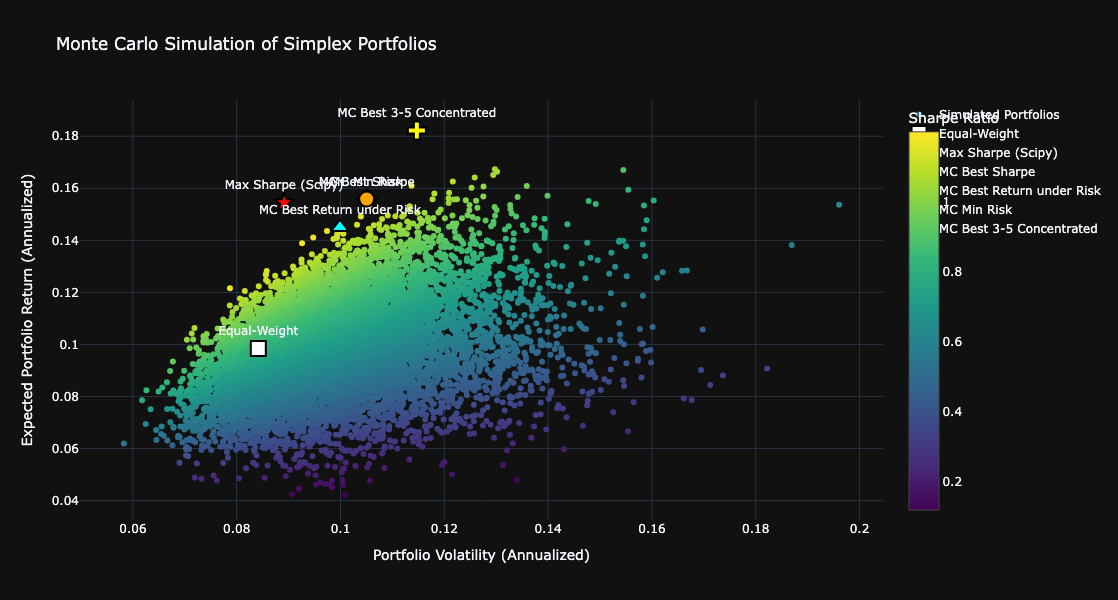

In [14]:
# Cell: Visualize Simulated Random Portfolios
import plotly.graph_objects as go

fig = go.Figure()

# Plot simulated portfolios
fig.add_trace(go.Scatter(
    x=portfolios_df["portfolio_volatility"],
    y=portfolios_df["expected_return"],
    mode="markers",
    marker=dict(
        color=portfolios_df["sharpe_ratio"],
        colorscale="Viridis",
        showscale=True,
        colorbar=dict(title="Sharpe Ratio")
    ),
    text=portfolios_df["fail_reason"],
    hoverinfo="x+y+text",
    name="Simulated Portfolios"
))

# Mark special portfolios
special_ports = [
    ("Equal-Weight", weights_table["equal_weight"], "white", "square"),
    ("Max Sharpe (Scipy)", weights_table["max_sharpe"], "red", "star"),
    ("MC Best Sharpe", weights_table["mc_max_sharpe"], "magenta", "diamond"),
    ("MC Best Return under Risk", weights_table["mc_max_ret_under_risk"], "cyan", "triangle-up"),
    ("MC Min Risk", weights_table["mc_min_risk"], "orange", "circle"),
    ("MC Best 3-5 Concentrated", weights_table["mc_best_concentrated_3_5"], "yellow", "cross")
]

for name, w, color, symbol_shape in special_ports:
    summary = generate_portfolio_summary(w, expected_returns, cov_matrix)
    fig.add_trace(go.Scatter(
        x=[summary["annualized_volatility"]],
        y=[summary["expected_return"]],
        mode="markers+text",
        text=[name],
        textposition="top center",
        marker=dict(color=color, size=15, symbol=symbol_shape, line=dict(color="black", width=2)),
        name=name
))

fig.update_layout(
    title="Monte Carlo Simulation of Simplex Portfolios",
    xaxis_title="Portfolio Volatility (Annualized)",
    yaxis_title="Expected Portfolio Return (Annualized)",
    template="plotly_dark",
    width=1000,
    height=600
)

fig.show()

In [15]:
# Cell: Save Portfolio Construction Weights
from src.data.loaders import save_parquet

# 1. Save all weights for comparison reference
weights_save_df = weights_table.reset_index(names="symbol")
save_parquet(weights_save_df, "data/signals/portfolio_construction_weights.parquet")
print("Saved portfolio construction weights to data/signals/portfolio_construction_weights.parquet")

# 2. Save the SELECTED optimal portfolio weights for Notebook 15 & 16
# We default to the best concentrated portfolio (3-5 stocks) selected by Monte Carlo
selected_col = "mc_best_concentrated_3_5"
selected_weights = weights_table[selected_col].to_frame("weight").reset_index(names="symbol")
save_parquet(selected_weights, "data/signals/selected_portfolio_weights.parquet")
print(f"Saved selected portfolio weights ({selected_col}) to data/signals/selected_portfolio_weights.parquet")
selected_weights


Saved portfolio construction weights to data/signals/portfolio_construction_weights.parquet
Saved selected portfolio weights (mc_best_concentrated_3_5) to data/signals/selected_portfolio_weights.parquet


,symbol,weight
0,ASP,0.000000
1,BID,0.000000
2,BWE,0.000000
3,GEG,0.000000
4,KLB,0.220350
5,LAF,0.000000
6,MBB,0.295139
7,MCM,0.000000
8,MSB,0.000000
9,NAB,0.000000
